# Project 1 · Notebook 1: Exploring NASA CMAPSS engine data

**Goal of the whole project:** predict the *remaining useful life* (RUL) of jet engines from sensor data, then show the results in a Power BI dashboard.

**Goal of this notebook:** load the data, understand it, compute RUL, and find which sensors actually matter.

**Rule:** type the code yourself instead of copy-pasting. Run each cell with Shift+Enter and read the output before moving on.

**Data:** download the CMAPSS dataset from Kaggle (search "NASA CMAPS" by behrad3d) and put `train_FD001.txt` in a folder called `data/` next to this notebook.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


## 2. Load the data

The file has no header and is separated by spaces. Each row is one engine at one time step ("cycle").

- 1 column: engine ID (`unit`)
- 1 column: time in cycles (`cycle`)
- 3 columns: operating settings
- 21 columns: sensor readings

In [2]:
cols = ['unit', 'cycle'] + [f'setting_{i}' for i in range(1, 4)] + [f'sensor_{i}' for i in range(1, 22)]

train = pd.read_csv('data/train_FD001.txt', sep=r'\s+', header=None, names=cols)
print(train.shape)
train.head()

(20631, 26)


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


**Check:** you should see about 20,600 rows and 26 columns. How many different engines are there?

In [3]:
print('Number of engines:', train['unit'].nunique())

Number of engines: 100


## 3. Compute Remaining Useful Life (RUL)

Every engine in the training data runs until it fails. So for each row:

**RUL = the engine's last cycle − the current cycle**

At the final cycle, RUL is 0 (the engine failed).

In [4]:
max_cycle = train.groupby('unit')['cycle'].max().rename('max_cycle')
train = train.merge(max_cycle, on='unit')
train['RUL'] = train['max_cycle'] - train['cycle']
train[['unit', 'cycle', 'max_cycle', 'RUL']].head(10)

,unit,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


## 4. How long do engines live?

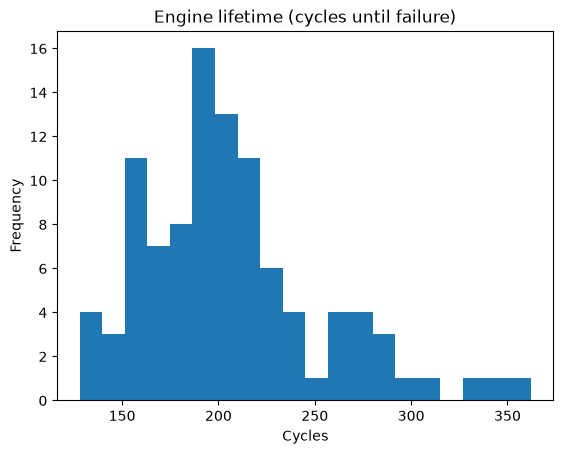

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: max_cycle, dtype: float64


In [5]:
max_cycle.plot(kind='hist', bins=20, title='Engine lifetime (cycles until failure)')
plt.xlabel('Cycles')
plt.show()

print(max_cycle.describe())

**Write down in your learning notebook:** the shortest, longest and average engine life.

## 5. Remove sensors that never change

A sensor whose value stays (almost) constant can't help predict failure. We find them by their standard deviation.

In [6]:
feature_cols = [c for c in cols if c.startswith('sensor') or c.startswith('setting')]
std = train[feature_cols].std().sort_values()
print(std)

constant = std[std < 1e-3].index.tolist()
print('\nAlmost constant, will drop:', constant)

setting_3    0.000000e+00
sensor_1     0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_10    0.000000e+00
sensor_16    3.469531e-18
sensor_5     5.329200e-15
setting_2    2.930621e-04
sensor_6     1.388985e-03
setting_1    2.187313e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

Almost constant, will drop: ['setting_3', 'sensor_1', 'sensor_19', 'sensor_18', 'sensor_10', 'sensor_16', 'sensor_5', 'setting_2']


In [7]:
useful = [c for c in feature_cols if c not in constant]
print(len(useful), 'useful columns:', useful)

16 useful columns: ['setting_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 6. How do sensors change as an engine approaches failure?

We plot a few useful sensors against RUL for 5 engines. The x-axis is reversed so failure (RUL 0) is on the right.

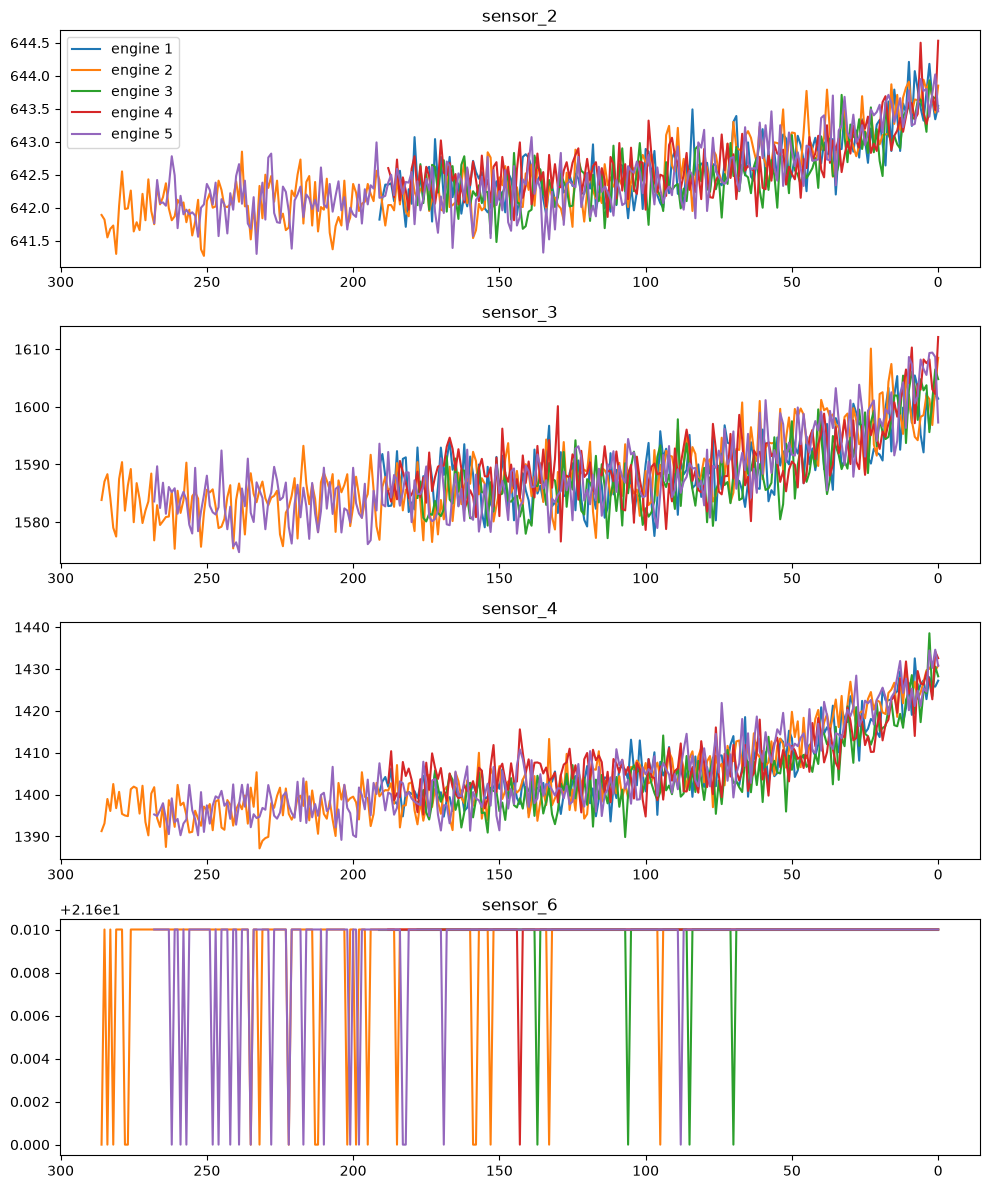

In [8]:
sample_units = train['unit'].unique()[:5]
sensors_to_plot = [c for c in useful if c.startswith('sensor')][:4]

fig, axes = plt.subplots(len(sensors_to_plot), 1, figsize=(10, 3 * len(sensors_to_plot)))
for ax, s in zip(axes, sensors_to_plot):
    for u in sample_units:
        d = train[train['unit'] == u]
        ax.plot(d['RUL'], d[s], label=f'engine {u}')
    ax.set_title(s)
    ax.invert_xaxis()
axes[0].legend()
plt.tight_layout()
plt.show()

## 7. Which sensors are most related to RUL?

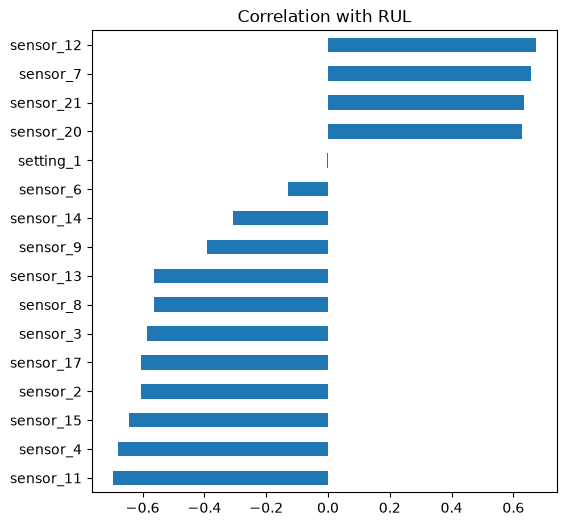

sensor_11   -0.696228
sensor_4    -0.678948
sensor_15   -0.642667
sensor_2    -0.606484
sensor_17   -0.606154
sensor_3    -0.584520
sensor_8    -0.563968
sensor_13   -0.562569
sensor_9    -0.390102
sensor_14   -0.306769
sensor_6    -0.128348
setting_1   -0.003198
sensor_20    0.629428
sensor_21    0.635662
sensor_7     0.657223
sensor_12    0.671983
Name: RUL, dtype: float64


In [9]:
corr = train[useful + ['RUL']].corr()['RUL'].drop('RUL').sort_values()
corr.plot(kind='barh', figsize=(6, 6), title='Correlation with RUL')
plt.show()
print(corr)

## 8. Save the cleaned data for the next notebook

In [10]:
import os
os.makedirs('data', exist_ok=True)
train[['unit', 'cycle'] + useful + ['RUL']].to_csv('data/train_FD001_clean.csv', index=False)
print('Saved', len(train), 'rows')

Saved 20631 rows


## 9. Your turn (answer these before Notebook 2)

1. Which 3 sensors have the strongest correlation with RUL? Do they go up or down as the engine wears out?
2. Plot your strongest sensor for 10 engines instead of 5. Do all engines show the same pattern?
3. Many papers cap RUL at 125 cycles, because early in life the engine looks healthy and exact RUL is unpredictable. Create a column `RUL_capped = RUL.clip(upper=125)` and plot it for one engine. Why might this help a model?
4. Write 3 sentences for your README: what problem this solves, what data you used, and one thing you discovered.

**Next:** Notebook 2 trains your first models (linear regression and random forest) and measures the error in cycles (RMSE).